# Задача 4.7
# События при встрече Ивана и Петра

## Условие
Иван и Пётр независимо приходят между 11 и 12 часами, ждут не более 15 минут и не позже 12:00. Найти вероятности A — встретились; B — не встретились; C — Ивану не пришлось ждать Петра; D — встретились после 11:30; E — Иван опоздал; F — встретились менее чем за 5 минут до конца часа. Для A провести $150000$ опытов.

## Теория с нуля и решение вручную
### 1. Координаты и смысл событий
Пусть $x$ — приход Ивана, $y$ — приход Петра в минутах после 11:00. Пара равномерна в квадрате $[0,60]^2$. Встреча возможна при $|x-y|\le15$; её время $\max(x,y)$. Ограничение ожидания концом часа не меняет условие встречи: оба прихода уже принадлежат этому часу.

### 2. Основные площади
Для A из квадрата вычитаем два треугольника с катетом 45:
$$P(A)=1-\frac{45^2}{60^2}=\frac7{16},\qquad P(B)=\frac9{16}.$$
Событие C понимаем как «Иван пришёл к уже ожидающему Петру и сразу встретился с ним»: $0\le x-y\le15$. Это половина полосы встречи:
$$P(C)=\frac{P(A)}2=\frac7{32}.$$
Для D из всех встреч вычитаем встречи в квадрате $[0,30]^2$. В этом малом квадрате площадь полосы равна $30^2-15^2=675$:
$$P(D)=\frac{1575-675}{3600}=\frac14.$$
Событие D безусловное: дополнительно делить на $P(A)$ не нужно.

### 3. Неоднозначность слова «опоздал»
В условии не назначен конкретный момент встречи. Для основного E примем смысл «Иван пришёл после того, как Пётр ушёл»: $x-y>15$. Это один треугольник:
$$P(E)=\frac{45^2}{2\cdot3600}=\frac9{32}.$$
Если под «опоздал» понимать просто «пришёл позже Петра», получится $P(x>y)=1/2$. Если «пришёл позже, но встреча состоялась», получится $7/32$. Эти трактовки выведены отдельно в коде. При ответе преподавателю сначала нужно уточнить определение события. Для C фраза «Иван просто пришёл не раньше Петра», без требования встречи, тоже дала бы $1/2$; здесь C включает состоявшуюся встречу.

### 4. Последние пять минут
F означает $A\cap\{\max(x,y)>55\}$. Площадь встреч с обоими приходами не позже 55 равна $55^2-40^2=1425$. Всего площадь встреч 1575:
$$P(F)=\frac{1575-1425}{3600}=\frac1{24}.$$
Проверка: F является частью D, а D — частью A. В коде эти включения выполняются для каждого опыта, а не только приблизительно по частотам.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

A: встреча: успехов 65745, знаменатель 150000
  частота = 0.43830000; ориентир 95%: [0.43578899; 0.44081101]
  теория = 0.43750000; разность = +0.00080000


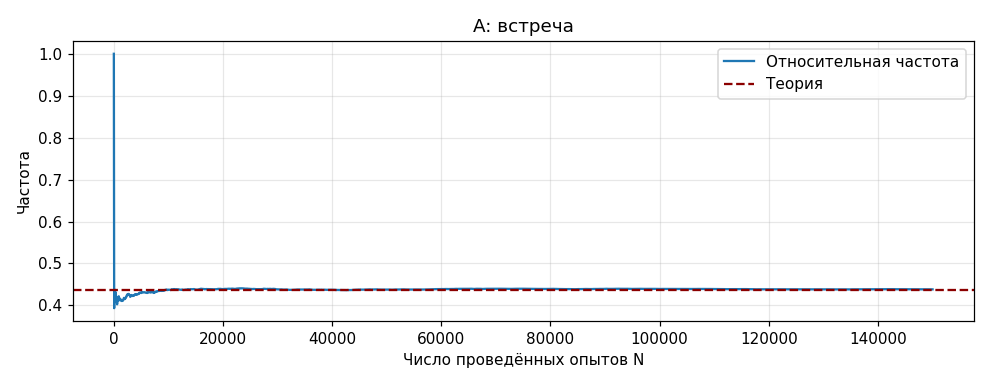

B: невстреча: успехов 84255, знаменатель 150000
  частота = 0.56170000; ориентир 95%: [0.55918899; 0.56421101]
  теория = 0.56250000; разность = -0.00080000


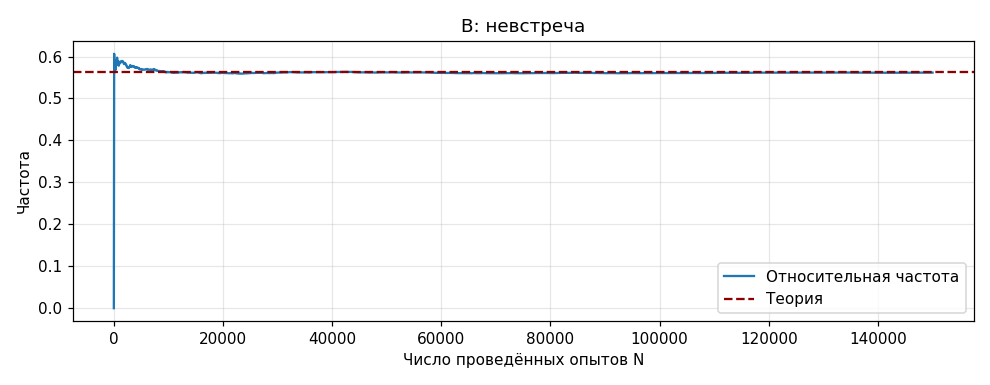

C: Иван сразу встретил ожидающего Петра: успехов 33013, знаменатель 150000
  частота = 0.22008667; ориентир 95%: [0.21798999; 0.22218334]
  теория = 0.21875000; разность = +0.00133667


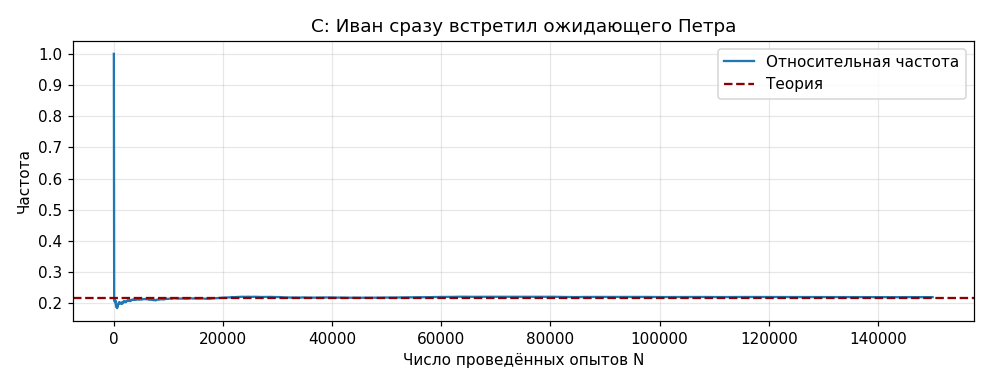

D: встреча после 11:30: успехов 37302, знаменатель 150000
  частота = 0.24868000; ориентир 95%: [0.24649252; 0.25086748]
  теория = 0.25000000; разность = -0.00132000


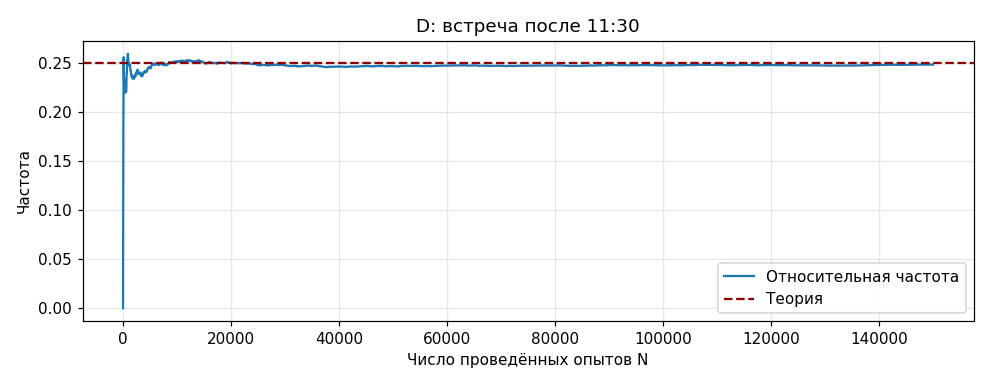

E: Иван пришёл после ухода Петра: успехов 41978, знаменатель 150000
  частота = 0.27985333; ориентир 95%: [0.27758145; 0.28212522]
  теория = 0.28125000; разность = -0.00139667


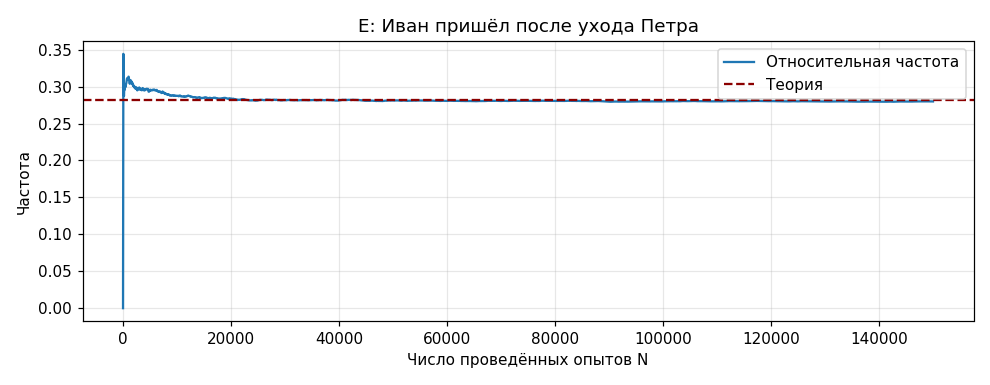

F: встреча после 11:55: успехов 6311, знаменатель 150000
  частота = 0.04207333; ориентир 95%: [0.04105737; 0.04308930]
  теория = 0.04166667; разность = +0.00040667


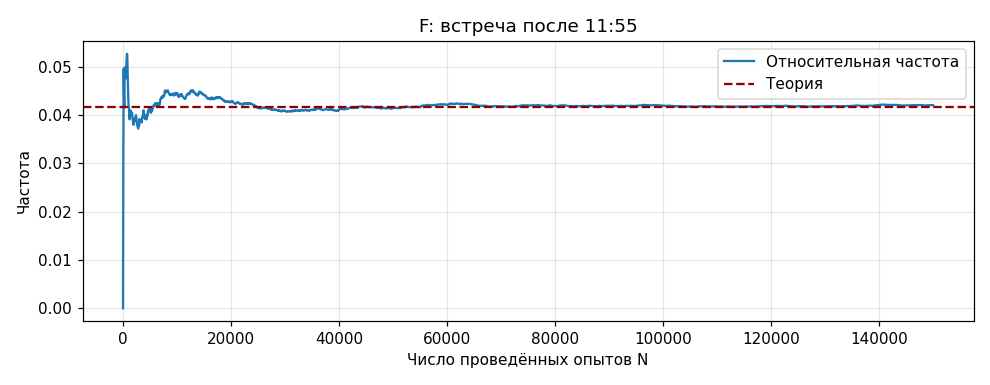

Другая трактовка E, Иван позже Петра: 0.49994 ; теория 1/2
Позже Петра, но успел встретиться: 0.22008666666666668 ; теория 7/32


In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
x = rng.uniform(0, 60, N)
y = rng.uniform(0, 60, N)
A = np.abs(x-y) <= 15
B = ~A
C = A & (x >= y)
D = A & (np.maximum(x, y) > 30)
E = x-y > 15
F = A & (np.maximum(x, y) > 55)
events = [('A: встреча', A, Fraction(7,16)), ('B: невстреча', B, Fraction(9,16)),
          ('C: Иван сразу встретил ожидающего Петра', C, Fraction(7,32)),
          ('D: встреча после 11:30', D, Fraction(1,4)),
          ('E: Иван пришёл после ухода Петра', E, Fraction(9,32)),
          ('F: встреча после 11:55', F, Fraction(1,24))]
for name, event, exact in events:
    report(event, name, exact)
print('Другая трактовка E, Иван позже Петра:', np.mean(x > y), '; теория 1/2')
print('Позже Петра, но успел встретиться:', np.mean(A & (x > y)), '; теория 7/32')
